<a href="https://colab.research.google.com/github/ckurtz/teaching_UPC_UFRMI/blob/main/selfsupervised_demos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# References

[Course Webpage](https://sites.google.com/view/berkeley-cs294-158-sp20/home)

[1] Pathak, Deepak, et al. "Context encoders: Feature learning by inpainting." Proceedings of the IEEE conference on computer vision and pattern recognition. 2016.

[2] Gidaris, Spyros, Praveer Singh, and Nikos Komodakis. "Unsupervised representation learning by predicting image rotations." arXiv preprint arXiv:1803.07728 (2018).

[3] Chen, Ting, et al. "A simple framework for contrastive learning of visual representations." arXiv preprint arXiv:2002.05709 (2020).

[4] Noroozi, Mehdi, and Paolo Favaro. "Unsupervised learning of visual representations by solving jigsaw puzzles." European Conference on Computer Vision. Springer, Cham, 2016.

[5] Wang, Xiaolong, Allan Jabri, and Alexei A. Efros. "Learning correspondence from the cycle-consistency of time." Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition. 2019.

[6] Oord, Aaron van den, Yazhe Li, and Oriol Vinyals. "Representation learning with contrastive predictive coding." arXiv preprint arXiv:1807.03748 (2018).

[7] Hénaff, Olivier J., et al. "Data-efficient image recognition with contrastive predictive coding." arXiv preprint arXiv:1905.09272 (2019).

[8] Tian, Yonglong, Dilip Krishnan, and Phillip Isola. "Contrastive multiview coding." arXiv preprint arXiv:1906.05849 (2019).

[9] He, Kaiming, et al. "Momentum contrast for unsupervised visual representation learning." arXiv preprint arXiv:1911.05722 (2019).

[10] Doersch, Carl, Abhinav Gupta, and Alexei A. Efros. "Unsupervised visual representation learning by context prediction." Proceedings of the IEEE International Conference on Computer Vision. 2015.

[11] Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "U-net: Convolutional networks for biomedical image segmentation." International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

# Getting Started
Go to **Runtime -> Change runtime type** and make sure **Hardward accelerator** is set to **GPU**

In [1]:
from pathlib import Path
import os
import sys

project = Path(r"G:\Vmi\M2\深度视觉\cs294-158-ssl")

if not (project / "deepul_helper").is_dir():
    raise FileNotFoundError(f"Projet introuvable : {project}")

os.chdir(project)
sys.path.insert(0, str(project))

import torch
from deepul_helper.demos import load_model_and_data, evaluate_accuracy

print("Import réussi")
print("Python :", sys.executable)
print("GPU disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Import réussi
Python : G:\anaconda3\envs\pytorch\python.exe
GPU disponible : True
GPU : NVIDIA GeForce RTX 4060 Laptop GPU


Run the cells below to download the necessary pretrained models. It should take a few minutes.

In [3]:
from pathlib import Path
import urllib.request
import zipfile
from tqdm.auto import tqdm

project = Path(r"G:\Vmi\M2\深度视觉\cs294-158-ssl")

def download_archive(name):
    archive = project / f"{name}.zip"
    partial = project / f"{name}.zip.part"

    if archive.exists():
        print(f"{archive.name} : déjà présent")
        return

    url = f"https://camille-kurtz.com/teaching/{name}.zip"

    with urllib.request.urlopen(url, timeout=60) as response:
        total = int(response.headers.get("Content-Length", 0))

        with open(partial, "wb") as output, tqdm(
            total=total or None,
            unit="B",
            unit_scale=True,
            desc=name
        ) as progress:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                output.write(chunk)
                progress.update(len(chunk))

    if total and partial.stat().st_size != total:
        raise IOError("Téléchargement incomplet")

    partial.replace(archive)
    print(f"{archive.name} : téléchargement terminé")

download_archive("data")

data:   0%|          | 0.00/4.23G [00:00<?, ?B/s]

data.zip : téléchargement terminé


In [4]:
download_archive("results")

results:   0%|          | 0.00/2.64G [00:00<?, ?B/s]

results.zip : téléchargement terminé


In [5]:
print("Extraction de data.zip…", flush=True)

with zipfile.ZipFile(project / "data.zip") as archive:
    archive.extractall(project)

print("Extraction terminée")

Extraction de data.zip…
Extraction terminée


In [6]:
print("Extraction de results.zip…", flush=True)

with zipfile.ZipFile(project / "results.zip") as archive:
    archive.extractall(project)

print("Extraction terminée")

Extraction de results.zip…
Extraction terminée


The models and demos shown were pre-trained. The code used for all the demos can be found in the github repo [here](https://github.com/wilson1yan/cs294-158-ssl). Follow the README to train models on CIFAR10 or ImageNet.

# Self-Supervised Learning Tasks
Self-supervised learning is a rapidly growing field, its success largely accelerated by growing compute and the vast amount of unlabeled data available for training. The hope is that by pretraining on specially designed self-supervised tasks, the models would be able to learn semantically meaningful representations to be used for downstream tasks. In the following demos, we will look at a few examples of these self-supervised tasks.

In [8]:
from deepul_helper.demos import load_model_and_data, evaluate_accuracy, display_nearest_neighbors, show_context_encoder_inpainting

%matplotlib inline

## Demo 1: Context Encoder [[1]](https://arxiv.org/abs/1604.07379)

The context encoder structures its self-supervised learning task by inpainting masked images. For example, the figure below shows different masking shapes, such as center masking, random block masking, and segmentation masking. Note that segmentation masking (c) is not purely self-supervised since we would need to train a image segmentation model which requires labels. However, the other two masking schemes (a) and (b) and purely self-supervised.

![](https://drive.google.com/uc?id=1fhzkULYTtyMGUUF2n9dlPayJSdcY5pRv)

More formally, the context encoder optimizes the following reconstruction loss:
$$\mathcal{L}_{rec} = \left\Vert \hat{M} \odot (x - F((1 - \hat{M})\odot x)) \right\Vert^2_2$$
where $\hat{M}$ is the masked region, $x$ is the image, and $F$ is the context encoder that tries to reconstruct the masked portion. In addition to the reconstruction loss, the paper introduces an adversarial loss that encourages more realistic inpaintings.
$$L_{adv} = \max_D \mathbb{E}_{x\in \chi} [\log(D(x)) + \log(1 - D(F((1-\hat{M})\odot x)))]$$
However, this demo does not use the adversarial portion of the loss.

### Example Code

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ContextEncoder(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes):
        super().__init__()
        input_channels = 3

        self.latent_dim = 4000

        # Encodes the masked image
        self.encoder = nn.Sequential(
            # 128 x 128 Input
            nn.Conv2d(input_channels, 64, 4, stride=2, padding=1), # 64 x 64
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 64, 4, stride=2, padding=1), # 32 x 32
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), # 16 x 16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), # 8 x 8
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, stride=2, padding=1), # 4 x 4
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, self.latent_dim, 4) # 1 x 1
        )

        # Only reconstructs the masked part of the image and not the whole image
        self.decoder = nn.Sequential(
           nn.BatchNorm2d(self.latent_dim),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(self.latent_dim, 512, 4, stride=1, padding=0), # 4 x 4
           nn.BatchNorm2d(512),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(512, 256, 4, stride=2, padding=1), # 8 x 8
           nn.BatchNorm2d(256),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 16 x 16
           nn.BatchNorm2d(128),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), # 32 x 32
           nn.BatchNorm2d(64),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(64, input_channels, 4, stride=2, padding=1), # 64 x 64
           nn.Tanh()
        )

        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        classifier = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(self.latent_dim, affine=False),
            nn.Linear(self.latent_dim, self.n_classes)
        )
        return classifier

    def forward(self, images):
        # Extract a 64 x 64 center from 128 x 128 image
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        # Mask out a 64 x 64 center with slight overlap
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        return dict(Loss=F.mse_loss(center_recon, images_center)), torch.flatten(z, 1)

    def encode(self, images):
        images_masked = images
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0
        return self.encoder(images_masked)

    def reconstruct(self, images):
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        images_masked[:, 0, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        images_recon = images_masked.clone()
        images_recon[:, :, 32:32+64, 32:32+64] = center_recon
        return images_masked, images_recon


### Inpainting Examples
For each pair of images, the left image is the masked input and the right the inpainted reconstruction.

Files already downloaded and verified
Files already downloaded and verified


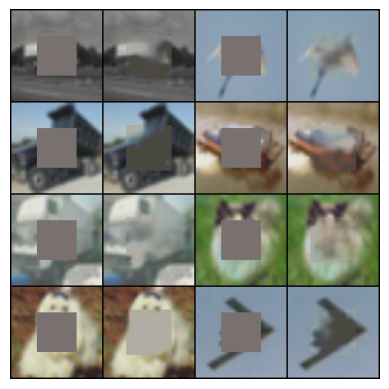

In [15]:
show_context_encoder_inpainting()

### Linear Classification
By design the model architecture is an encoder -> decoder module. We can use the bottleneck layer as our learned representation. Below, we show linear classification accuracy results on CIFAR10 using the learned representations.

In [11]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('context_encoder')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Files already downloaded and verified
Files already downloaded and verified
Train Set
Top 1 Accuracy: 53.24, Top 5 Accuracy: 94.094

Test Set
Top 1 Accuracy: 45.78, Top 5 Accuracy: 90.29



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


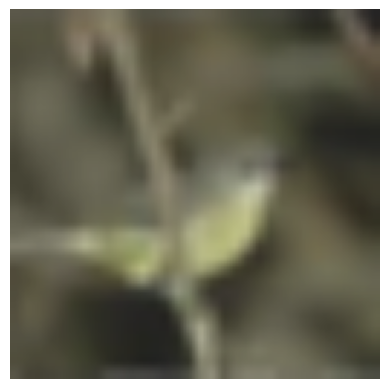

Top 16 Nearest Neighbors (in latent space)


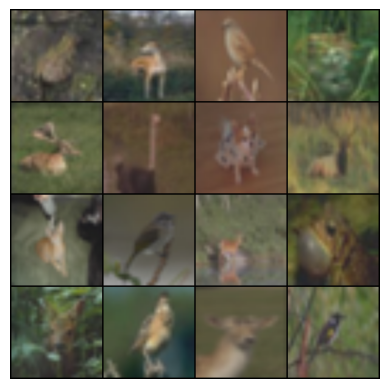

Image 2


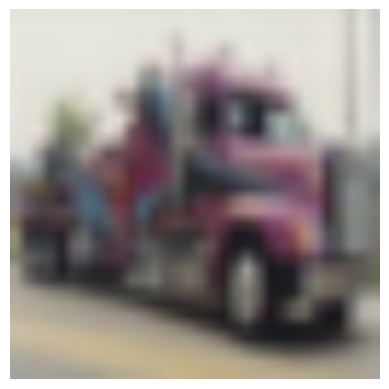

Top 16 Nearest Neighbors (in latent space)


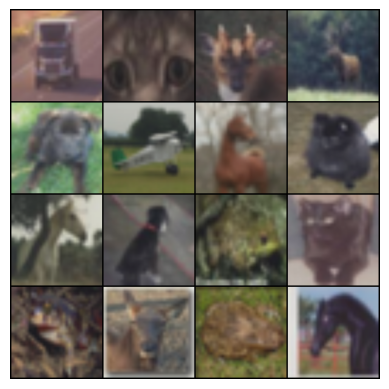

Image 3


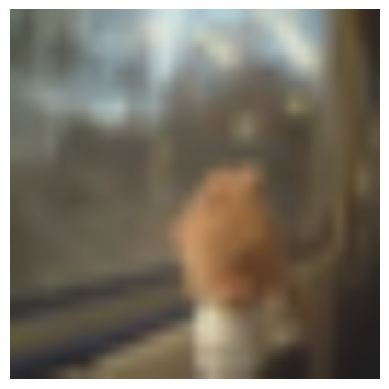

Top 16 Nearest Neighbors (in latent space)


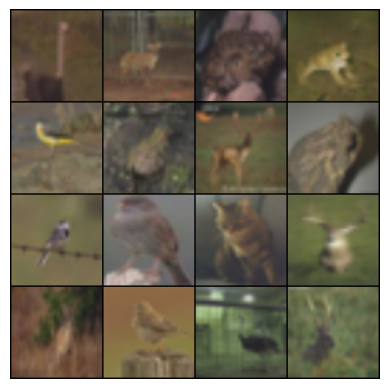

Image 4


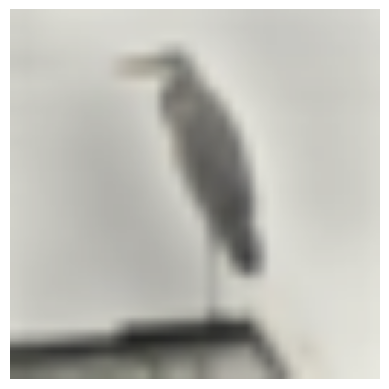

Top 16 Nearest Neighbors (in latent space)


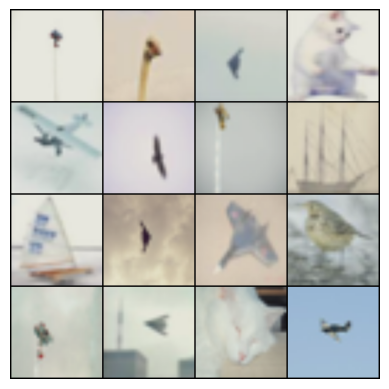

In [12]:
display_nearest_neighbors('context_encoder', model, test_loader)

## Demo 2: Rotation Prediction [[2]](https://arxiv.org/abs/1803.07728)

In this paper, the authors show that accurately predicting the degrees of rotation in images is a self-supervised learning task that learns good representations for downstream tasks.

![](https://drive.google.com/uc?id=1eHXLH-N_6uMGRzdf1Wjnga26qlS5-FRv)

More specifically, the authors showed that training a common CNN architecture (AlexNet, ResNet) on the rotation task learns semantically interpretable convolutional masks similar to those learned in supervised learning.

### Example Code

In [16]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


class RotationPrediction(nn.Module):
    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    def __init__(self, dataset, n_classes):
        super().__init__()
        if dataset == 'cifar10':
            self.model = NetworkInNetwork()
            self.latent_dim = 192 * 8 * 8
            self.feat_layer = 'conv2'
        elif 'imagenet' in dataset:
            self.model = AlexNet()
            self.latent_dim = 256 * 13 * 13
            self.feat_layer = 'conv5'
        else:
            raise Exception('Unsupported dataset:', dataset)
        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        if self.dataset == 'cifar10':
            classifier = nn.Sequential(
                Flatten(),
                nn.BatchNorm1d(self.latent_dim, affine=False),
                nn.Linear(self.latent_dim, self.n_classes)
            )
        elif 'imagenet' in self.dataset:
            classifier = nn.Sequential(
                nn.AdaptiveMaxPool2d((6, 6)),
                nn.BatchNorm2d(256, affine=False),
                Flatten(),
                nn.Linear(256 * 6 * 6, self.n_classes)
            )
        else:
            raise Exception('Unsupported dataset:', dataset)
        return classifier

    def forward(self, images):
        batch_size = images.shape[0]
        images, targets = self._preprocess(images)
        targets = targets.to(images.get_device())

        # logits是四种旋转角度的分数
        logits, zs = self.model(images, out_feat_keys=('classifier', self.feat_layer))
        loss = F.cross_entropy(logits, targets)
        # 计算准确度
        pred = logits.argmax(dim=-1)
        correct = pred.eq(targets).float().sum()
        acc = correct / targets.shape[0] * 100.

        return dict(Loss=loss, Acc1=acc), zs[:batch_size]

    def encode(self, images):
        zs = self.model(images, out_feat_keys=(self.feat_layer,))
        return zs

    def _preprocess(self, images):
        batch_size = images.shape[0]
        images_90 = torch.flip(images.transpose(2, 3), (2,))
        images_180 = torch.flip(images, (2, 3))
        images_270 = torch.flip(images, (2,)).transpose(2, 3)
        images_batch = torch.cat((images, images_90, images_180, images_270), dim=0)
        targets = torch.arange(4).long().repeat(batch_size)
        targets = targets.view(batch_size, 4).transpose(0, 1)
        targets = targets.contiguous().view(-1)
        return images_batch, targets

### Linear Classification
We can use the feature maps in the later convolutional layers of the pretrained model as our learned representation for linear classification.

In [17]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('rotation')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Files already downloaded and verified
Files already downloaded and verified
Train Set
Top 1 Accuracy: 79.458, Top 5 Accuracy: 99.104

Test Set
Top 1 Accuracy: 79.91, Top 5 Accuracy: 99.12



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


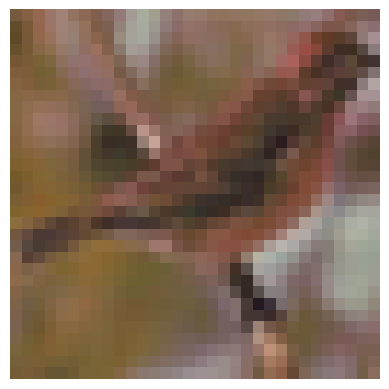

Top 16 Nearest Neighbors (in latent space)


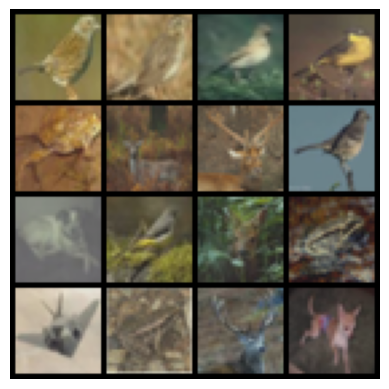

Image 2


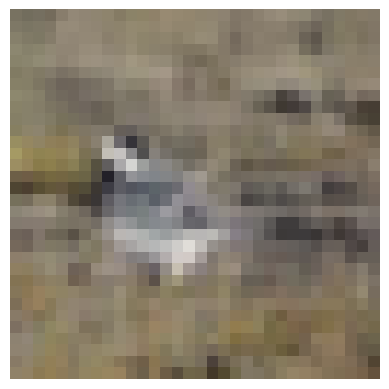

Top 16 Nearest Neighbors (in latent space)


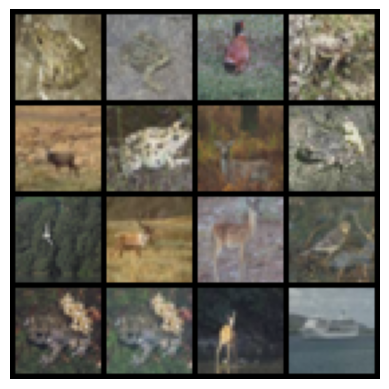

Image 3


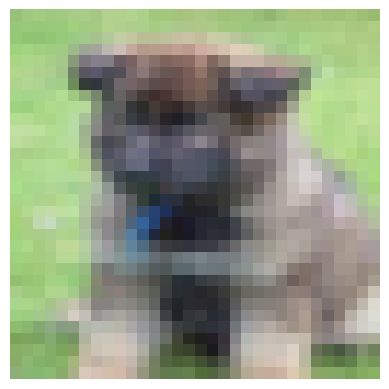

Top 16 Nearest Neighbors (in latent space)


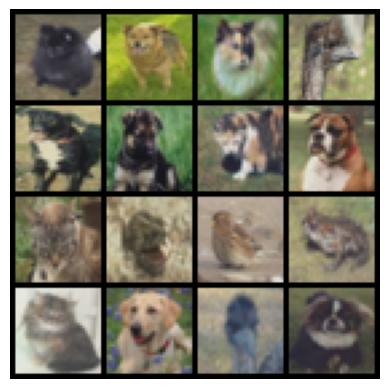

Image 4


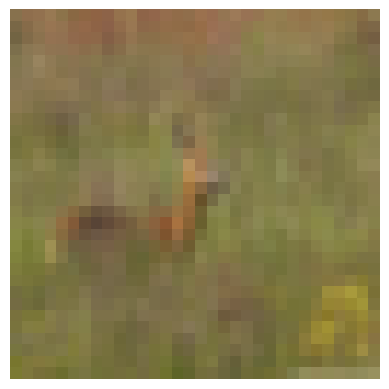

Top 16 Nearest Neighbors (in latent space)


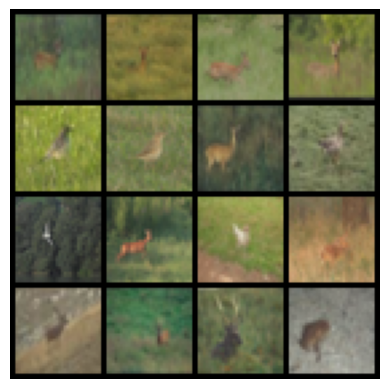

In [18]:
display_nearest_neighbors('rotation', model, test_loader)

## Demo 3: SimCLR [[3]](https://arxiv.org/abs/2002.05709)

SimCLR is a contrastive learning framework to learn strong visual representations. An image $x$ is processed using data augmentation to produce two variants $x_i$ and $x_j$ which are both fed into encoder $f$ (a CNN) and projection head $g$ (a small MLP). The models optimize a contrastive loss to maximally align projected latents $z_i, z_j$. We consider $x_i, x_j$ as a positive pair, and any other $x_i, x_k$ pairs (i.e. different images in the same batch) are negative pairs. A visual diagram of the training procedure is shown below (from the paper).

![](https://drive.google.com/uc?id=1XW1uIkUTMSa0DZncivSYXzM5gA5FIhF6)

More formally, the loss between positive example $z_i, z_j$ is:
$$\ell_{i,j} = -\log{\frac{\exp(\text{sim}(z_i, z_j)/\tau)}{\sum_{k=1}^{2N}\mathbb{1}_{[k\neq i]}\exp(\text{sim}(z_i, z_k)/\tau)}}$$
where $\text{sim}(z_i, z_j) = z_i^Tz_j / (\left\Vert z_i \right\Vert \left\Vert z_j \right\Vert)$. The loss function can also be interpreted as a standard cross entropy loss to classify positive samples where logits are constructed using a given similarity function.

Note: A common idea in contrastive learning methods is that a larger batch means more negative samples. Therefore, these methods usually benefit the most from large-batch learning compared to other self-supervised learning tasks.

### Example Code

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from deepul_helper.resnet import resnet_v1
from deepul_helper.batch_norm import SyncBatchNorm, BatchNorm1d

# Some code adapted from https://github.com/sthalles/SimCLR
class SimCLR(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes, dist=None):
        super().__init__()
        self.temperature = 0.5
        self.projection_dim = 128

        if dataset == 'cifar10':
            resnet = resnet_v1((3, 32, 32), 50, 1, cifar_stem=True)
            resnet = SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048
        elif 'imagenet' in dataset:
            resnet = resnet_v1((3, 128, 128), 50, 1, cifar_stem=False)
            if dist is not None:
                resnet = nn.SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048

        self.proj = nn.Sequential(
            nn.Linear(self.latent_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim),
            nn.ReLU(inplace=True),
            nn.Linear(self.projection_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim, center=False)
        )

        self.dataset = dataset
        self.n_classes = n_classes
        self.dist = dist

    def construct_classifier(self):
        return nn.Sequential(nn.Linear(self.latent_dim, self.n_classes))

    def forward(self, images):
        n = images[0].shape[0]
        xi, xj = images
        hi, hj = self.encode(xi), self.encode(xj) # (N, latent_dim)
        zi, zj = self.proj(hi), self.proj(hj) # (N, projection_dim)
        zi, zj = F.normalize(zi), F.normalize(zj)

        # Each training example has 2N - 2 negative samples
        # 2N total samples, but exclude the current and positive sample

        if self.dist is None:
            zis = [zi]
            zjs = [zj]
        else:
            zis = [torch.zeros_like(zi) for _ in range(self.dist.get_world_size())]
            zjs = [torch.zeros_like(zj) for _ in range(self.dist.get_world_size())]

            self.dist.all_gather(zis, zi)
            self.dist.all_gather(zjs, zj)

        z1 = torch.cat((zi, zj), dim=0) # (2N, projection_dim)
        z2 = torch.cat(zis + zjs, dim=0) # (2N * n_gpus, projection_dim)

        sim_matrix = torch.mm(z1, z2.t()) # (2N, 2N * n_gpus)
        sim_matrix = sim_matrix / self.temperature
        # Mask out same-sample terms
        n_gpus = 1 if self.dist is None else self.dist.get_world_size()
        rank = 0 if self.dist is None else self.dist.get_rank()
        sim_matrix[torch.arange(n), torch.arange(rank*n, (rank+1)*n)]  = -float('inf')
        sim_matrix[torch.arange(n, 2*n), torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n)] = -float('inf')

        targets = torch.cat((torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n),
                             torch.arange(rank*n, (rank+1)*n)), dim=0)
        targets = targets.to(sim_matrix.get_device()).long()

        loss = F.cross_entropy(sim_matrix, targets, reduction='sum')
        loss = loss / n
        return dict(Loss=loss), hi

    def encode(self, images):
        return self.resnet(images[0])

    def get_features(self, images):
        return self.resnet.get_features(images)


### Linear Classification
We can use the encoded vector $h_i$ as our latent representation.

In [20]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('simclr')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Files already downloaded and verified
Files already downloaded and verified
Train Set
Top 1 Accuracy: 90.25, Top 5 Accuracy: 99.49

Test Set
Top 1 Accuracy: 92.84, Top 5 Accuracy: 99.87



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


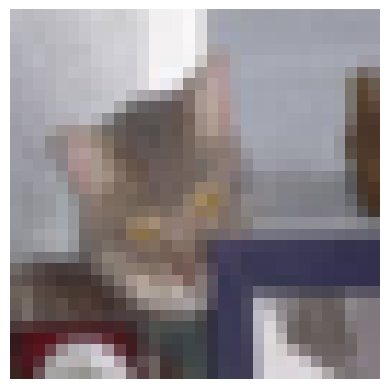

Top 16 Nearest Neighbors (in latent space)


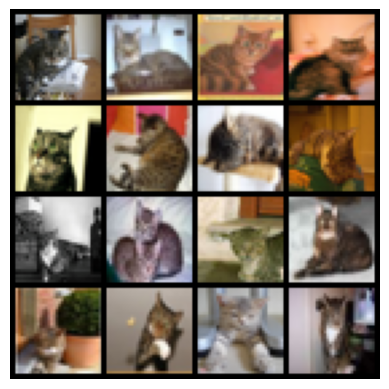

Image 2


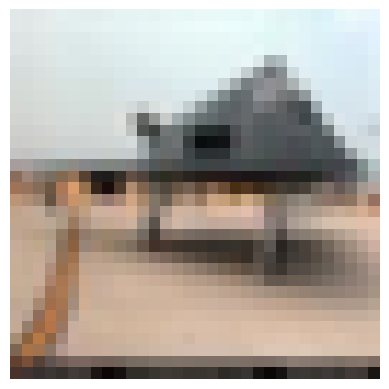

Top 16 Nearest Neighbors (in latent space)


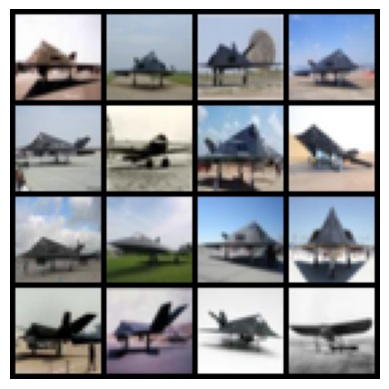

Image 3


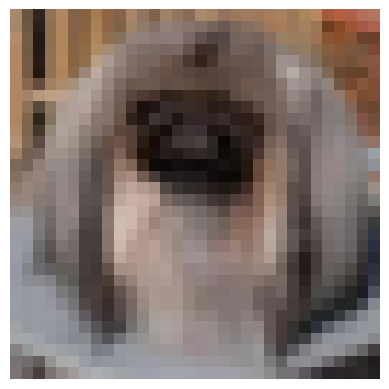

Top 16 Nearest Neighbors (in latent space)


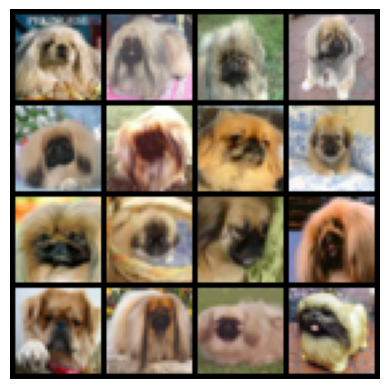

Image 4


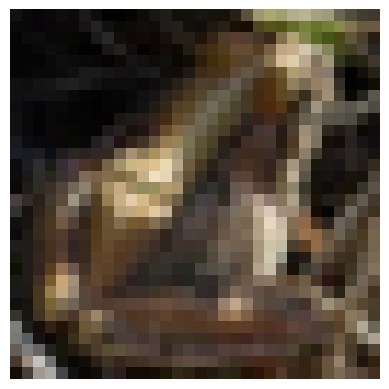

Top 16 Nearest Neighbors (in latent space)


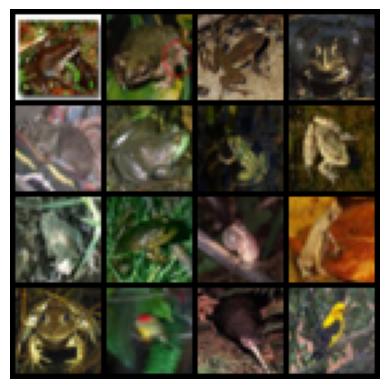

In [21]:
display_nearest_neighbors('simclr', model, test_loader)

## Other Tasks
In addition to the above tasks, prior work has also investigated other self-superivsed tasks such as solving jigsaw puzzles [[4]](https://arxiv.org/abs/1603.09246), cycle-consistency [[5]](https://arxiv.org/abs/1903.07593), contrastive learning [[6]](https://arxiv.org/abs/1807.03748)[[7]](https://arxiv.org/abs/1905.09272)[[8]](https://arxiv.org/abs/1906.05849)[[9]](https://arxiv.org/abs/1911.05722), and patch prediction [[10]](https://arxiv.org/abs/1505.05192). See [here](https://github.com/jason718/awesome-self-supervised-learning) for a great resource on more self-supervised learning papers.

# Demo 4: Using Representations for Downstream Tasks

After pretraining a model on a self-supervised learning task, we can use it for other downstream tasks. In this demo, we use the pre-trained ResNet50 backbone from training SimCLR on a subset of ImageNet to learn a semantic segmentation model on Pascal VOC 2012. We use a simple U-Net [[11]](https://arxiv.org/abs/1505.04597) architecture with skip connections across feature maps between the SimCLR encoder and learned upsampling decoder. We do not fine-tune the SimCLR ResNet50 backbone, and only optimize the upsampling portion.

![](https://drive.google.com/uc?id=19dxxcwof0IA0jyv0VCl4rnZZf3ajA22s)

The training script can be found in `train_segmentation.py` [here](https://github.com/wilson1yan/cs294-158-ssl/blob/master/train_segmentation.py).

## Example Code

In [22]:
# Code adapted from https://github.com/qubvel/segmentation_models.pytorch

import torch
import torch.nn as nn
import torch.nn.functional as F
from deepul_helper.resnet import NormReLU

class SegmentationModel(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, n_classes):
        super().__init__()

        decoder_channels = (512, 256, 128, 64, 32)
        encoder_channels = (2048, 1024, 512, 256, 64) # Starting from head (resnet 50)

        # Construct decoder blocks
        in_channels = [encoder_channels[0]] + list(decoder_channels[:-1])
        skip_channels = list(encoder_channels[1:]) + [0]
        out_channels = decoder_channels
        blocks = [
            DecoderBlock(in_ch, skip_ch, out_ch)
            for in_ch, skip_ch, out_ch in zip(in_channels, skip_channels, out_channels)
        ]
        self.dec_blocks = nn.ModuleList(blocks)

        # Segmentation head for output prediction
        self.seg_head = nn.Conv2d(decoder_channels[-1], n_classes, kernel_size=3, padding=1)

    def forward(self, features, targets):
        features = features[1:] # remove first skip with same spatial resolution
        features = features[::-1] # reverse channels to start from head of encoder

        skips = features[1:]
        x = features[0]
        for i, decoder_block in enumerate(self.dec_blocks):
            skip = skips[i] if i < len(skips) else None
            x = decoder_block(x, skip)

        logits = self.seg_head(x)
        loss = F.cross_entropy(logits, targets)

        return dict(Loss=loss), logits


class DecoderBlock(nn.Module):
    def __init__(
            self,
            in_channels,
            skip_channels,
            out_channels,
    ):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels,
                      kernel_size=3, padding=1),
            NormReLU((out_channels, None, None)), # only care about channel dim for BN
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            NormReLU((out_channels, None, None))
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        x = self.conv1(x)
        x = self.conv2(x)
        return x

## Segmentation Results
Below, we show a random subset of segmentations from the trained model. Every set of 3 images consists of the original image, the labeled segmentation, and the predicted segmentation.

Using downloaded and verified file: data\pascalvoc2012\VOCtrainval_11-May-2012.tar
Extracting data\pascalvoc2012\VOCtrainval_11-May-2012.tar to data\pascalvoc2012
Using downloaded and verified file: data\pascalvoc2012\VOCtrainval_11-May-2012.tar
Extracting data\pascalvoc2012\VOCtrainval_11-May-2012.tar to data\pascalvoc2012


G:\Vmi\M2\深度视觉\cs294-158-ssl\deepul_helper\demos.py:164: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(osp.join('results', 'imagenet100_simclr', 'seg_model

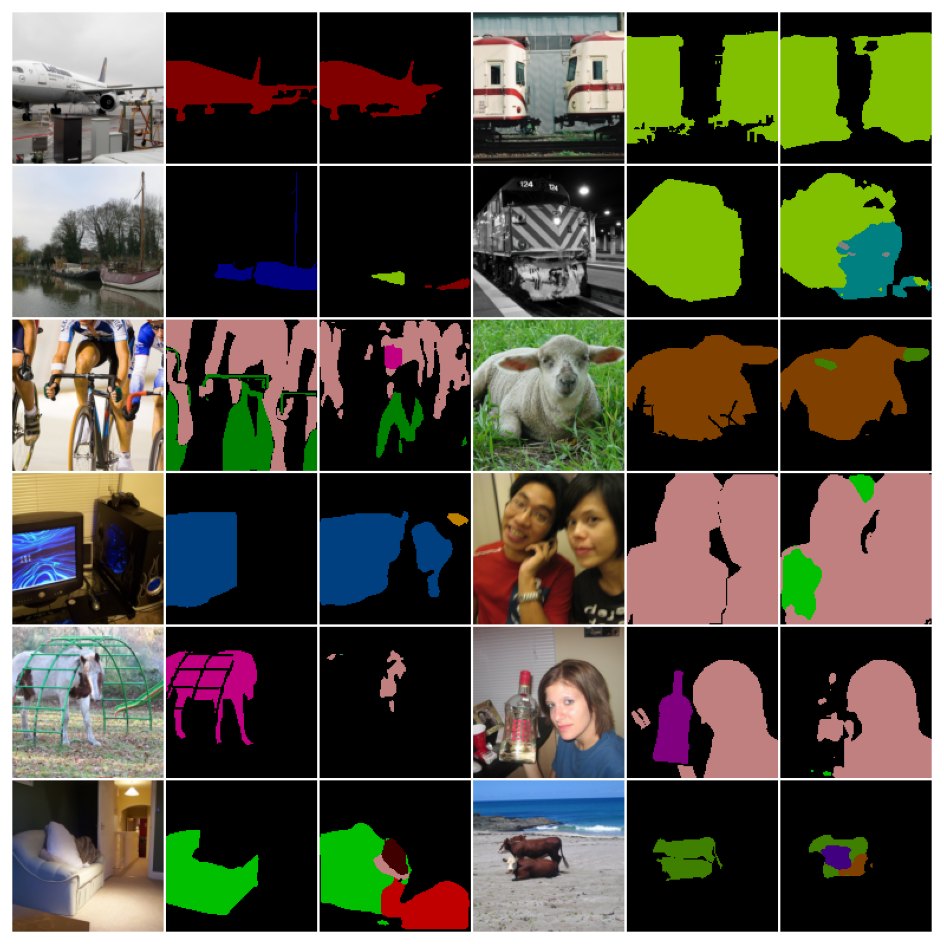

In [23]:
from deepul_helper.demos import show_segmentation
show_segmentation()

# Demo 5: Avoiding Trivial Representations in Self-Supervised Tasks

When designing a self-supervised learning task, it is important to make sure that no trivial solutions exists. In general, a learned solution is trivial if the model is able to successfully complete its task by taking advantage of low-level features. As a result, it doesn't learn a good representation so downstream performance is bad.

For example, in the jigsaw [[4]](https://arxiv.org/abs/1603.09246) task, a model can "cheat" by just looking at the boundary textures of the jigsaw pieces, or following and matching straight lines across different pieces. These issues can generally be fixed by ranndom cropping, shifting, and spacially jittering.

We look at two other less obvious aspects of images that may reduce performance.

## Chromatic Aberration

Chromatic aberration occurs when the different focal lengths of light results in the light not meeting all at the same point.
![from wikipedia](https://drive.google.com/uc?id=1PYGoQWnH0aAeiE_8t4ef5WDcq1UIQQ5t)

A example of very apparent chromatic aberration is shown below, where the green and magenta colors are clearly offset with each other:

![](https://drive.google.com/uc?id=1M1B6kV6ddBwyJse3FQT8_XBTeqs5s5WL)

Chromatic aberration generally becomes a problem in patch-based self-supervised learning tasks that design, such as solving jigsaw puzzles, or predicintg the correct location of a patch in an image In this case, the model can take advantage of the low-level chromatic aberration features to get a strong idea of where the patch is located without understanding the actual context.

Below is a quick demo of chromatic aberration in more realistic images, and possible fixes. Note that in general, chromatic aberration is fairly hard to spot with the naked eye, but deep learning models are still able to use it to their advantage.

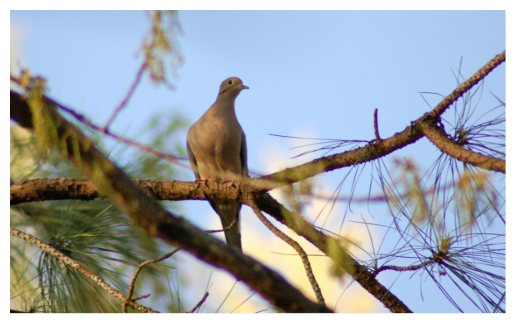

In [24]:
from PIL import Image
import matplotlib.pyplot as plt

# You can see some chromatic aberration in the purple fringes around the branches

image = Image.open('sample_images/chrom_ab_demo.png')
plt.figure()
plt.axis('off')
plt.imshow(image)
plt.show()

Chromatic aberration is generally fixed through conversion to grayscale, or color dropping. Color dropping works by dropping 2 of the color channels and replacing them with random noise uniform or Gaussian noise.

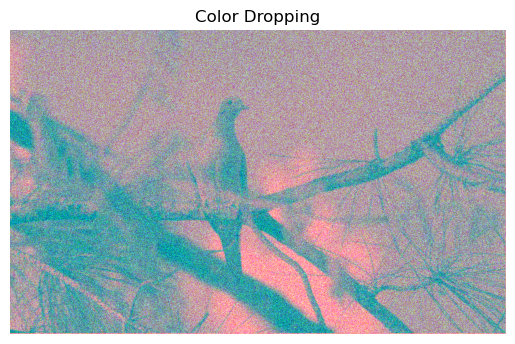

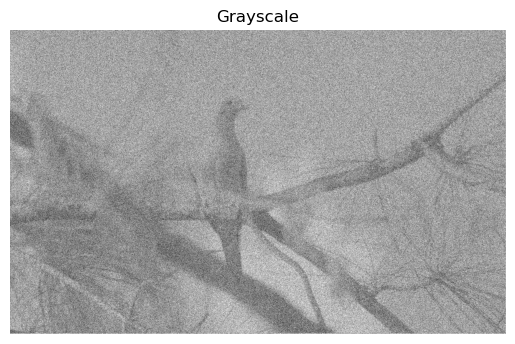

In [25]:
import numpy as np

# Color Dropping
# We will drop all channels except R
image_cpy = image.copy()
pixels = image_cpy.load()

arr = np.array(image_cpy)
std_R = np.std(arr[:, :, 0])
mean_G, mean_B = np.mean(arr[:, :, 1]), np.mean(arr[:, :, 2])

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j] # (R, G, B, A)
    R, A = p[0], p[3]
    G = int(np.random.randn() * std_R + mean_G)
    B = int(np.random.randn() * std_R + mean_B)

    # ici?
    # pixels[i, j] = (R, G, p[2], p[3])
    pixels[i, j] = (R, G, B, p[3])

plt.figure()
plt.title('Color Dropping')
plt.axis('off')
plt.imshow(image_cpy)
plt.show()

# Grayscale
image_cpy2 = image.copy()
pixels2 = image_cpy2.load()

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j]
    G = int(0.3 * p[0] + 0.59 * p[1] + 0.11 * p[2])
    pixels2[i, j] = (G, G, G, 255)

plt.figure()
plt.title('Grayscale')
plt.axis('off')
plt.imshow(image_cpy2)
plt.show()

## Color Intensity Histograms

In the SimCLR paper, the authors show that the histogram of color intensities of different patches within the same image have very similar histograms, which may degrade training by encouraging models to look at low-level (pixel intensity) features to solve self-supervised tasks that involve matching positive patches of the same image.

Below, we run a similar demo to what was demonstrated in the paper

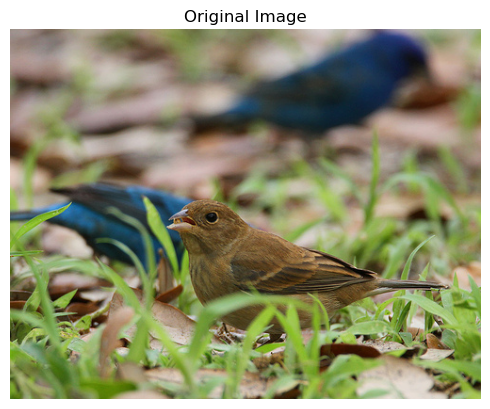

In [26]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Original Image')
plt.axis('off')
plt.imshow(image)
plt.show()

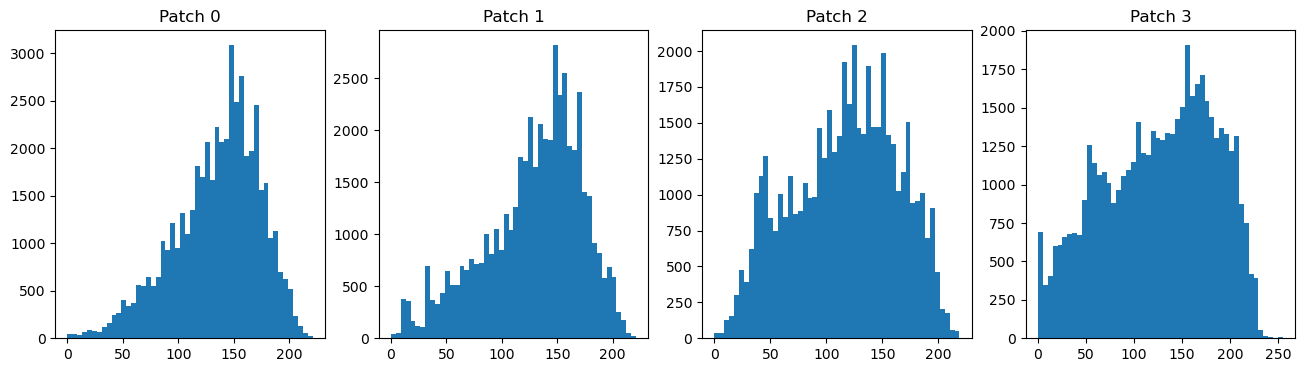

In [27]:
import numpy as np
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()

Now we apply color jittering to mitigate this effect

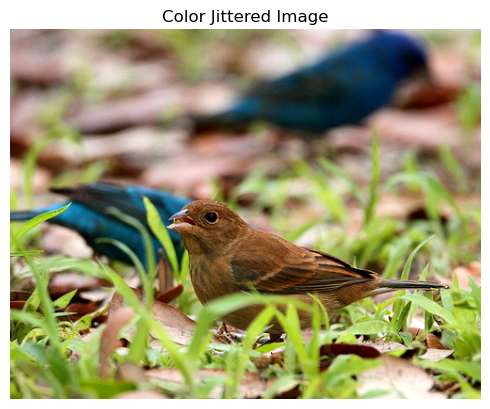

In [28]:
from torchvision import transforms

color_jitter = transforms.ColorJitter(0.3, 0.3, 0.3, 0.3)
jitter_img = color_jitter(image)

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Color Jittered Image')
plt.axis('off')
plt.imshow(jitter_img)
plt.show()

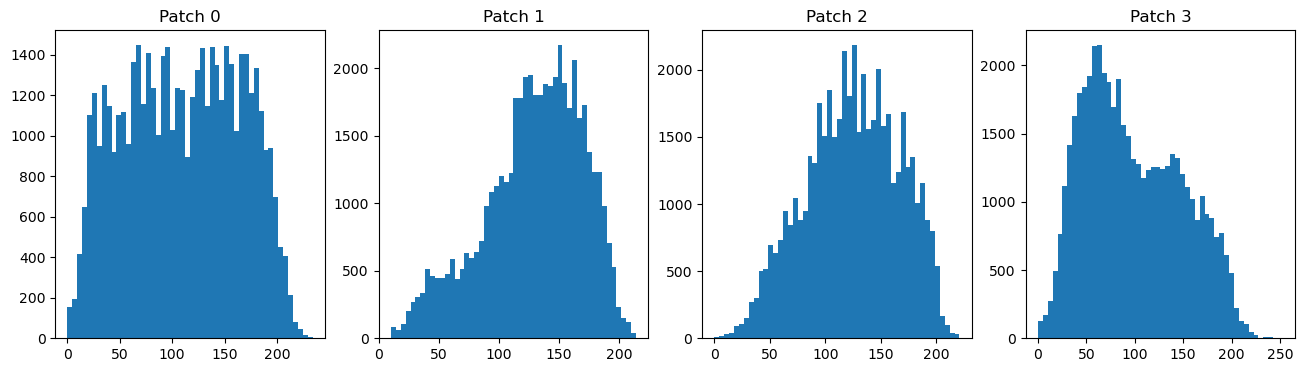

In [29]:
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()

# Travail personnel

## 1. Comparaison des représentations sur CIFAR10

In [30]:
from deepul_helper.demos import evaluate_classifier
import pandas as pd

def collect_accuracy(model, linear_classifier, train_loader, test_loader):
    # Évaluer sur les ensembles d'entraînement et de test
    train_acc1, train_acc5 = evaluate_classifier(
        model, linear_classifier, train_loader
    )
    test_acc1, test_acc5 = evaluate_classifier(
        model, linear_classifier, test_loader
    )

    # Retourner les résultats
    return {
        "Train Top-1 (%)": float(train_acc1),
        "Train Top-5 (%)": float(train_acc5),
        "Test Top-1 (%)": float(test_acc1),
        "Test Top-5 (%)": float(test_acc5)
    }

In [31]:
from deepul_helper.demos import load_model_and_data, evaluate_classifier
methods = ['context_encoder', 'rotation', 'simclr']
rows = []

for method in methods:
    print(f"Évaluation : {method}", flush=True)

    model, linear_classifier, train_loader, test_loader = (
        load_model_and_data(method)
    )

    scores = collect_accuracy(
        model, linear_classifier, train_loader, test_loader
    )

    rows.append({"Méthode": method, **scores})

results = pd.DataFrame(rows)
display(results)

Évaluation : context_encoder
Files already downloaded and verified
Files already downloaded and verified
Évaluation : rotation
Files already downloaded and verified
Files already downloaded and verified
Évaluation : simclr
Files already downloaded and verified
Files already downloaded and verified


,Méthode,Train Top-1 (%),Train Top-5 (%),Test Top-1 (%),Test Top-5 (%)
0,context_encoder,53.240,94.094,45.78,90.29
1,rotation,79.432,99.146,79.91,99.12
2,simclr,90.108,99.478,92.84,99.87


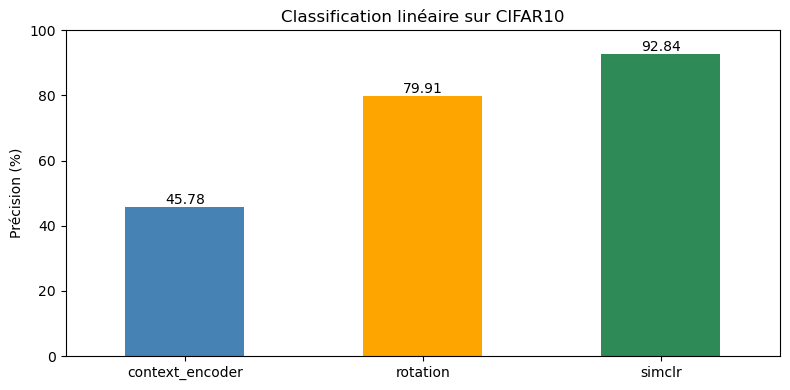

In [32]:
import matplotlib.pyplot as plt

# Comparer la précision Top-1 sur le test
ax = results.plot.bar(
    x="Méthode",
    y="Test Top-1 (%)",
    legend=False,
    rot=0,
    color=["steelblue", "orange", "seagreen"],
    figsize=(8, 4)
)

ax.set_ylabel("Précision (%)")
ax.set_xlabel("")
ax.set_title("Classification linéaire sur CIFAR10")
ax.set_ylim(0, 100)

# Afficher les valeurs au-dessus des barres
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.tight_layout()
plt.show()

### Analyse des résultats

SimCLR obtient la meilleure précision Top-1 sur le test
(92,84 %), suivi de la prédiction de rotation (79,91 %)
et du Context Encoder (45,77 %).

Dans cette expérience, les représentations de SimCLR sont
les plus efficaces pour la classification linéaire sur CIFAR10.
Cependant, les architectures et les conditions de préentraînement
diffèrent : cet écart ne peut pas être attribué uniquement
à la tâche auto-supervisée.

## 2. Comparaison sur CIFAR100

### 2.1 Rotation Prediction sur CIFAR100

100%|███████████████████████████████████████████████████████████████████████████████| 169M/169M [01:36<00:00, 1.75MB/s]


Extracting data\cifar-100-python.tar.gz to data
Files already downloaded and verified
Images d'entraînement : 50000
Images de test : 10000
Nombre de classes : 100
Taille de l'image : (32, 32)
Classe : cattle


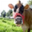

In [34]:
from torchvision.datasets import CIFAR100

# Chargement de CIFAR100
cifar100_train = CIFAR100(
    root="data",
    train=True,
    download=True
)

cifar100_test = CIFAR100(
    root="data",
    train=False,
    download=True
)

print("Images d'entraînement :", len(cifar100_train))
print("Images de test :", len(cifar100_test))
print("Nombre de classes :", len(cifar100_train.classes))

image, label = cifar100_train[0]
print("Taille de l'image :", image.size)
print("Classe :", cifar100_train.classes[label])
display(image)

In [35]:
from torch.utils.data import DataLoader
from torchvision.datasets import CIFAR100

# Charger le modèle préentraîné
model, _, _, original_test_loader = load_model_and_data('rotation')

# Réutiliser la transformation d'évaluation du modèle
transform = original_test_loader.dataset.transform

train_dataset = CIFAR100(
    root="data", train=True, download=False,
    transform=transform
)

test_dataset = CIFAR100(
    root="data", train=False, download=False,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=128,
    shuffle=True, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=128,
    shuffle=False, num_workers=2
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)
print("Labels :", labels.shape)

Files already downloaded and verified
Files already downloaded and verified
Images : torch.Size([128, 3, 32, 32])
Labels : torch.Size([128])


In [36]:
import torch

device = next(model.parameters()).device
model.eval()

def extract_features(model, loader):
    features = []
    labels = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)

            z = model.encode(images)
            z = z.flatten(start_dim=1)

            features.append(z.cpu())
            labels.append(targets.cpu())

    return torch.cat(features), torch.cat(labels)

In [37]:
print("Extraction des caractéristiques : train", flush=True)
X_train, y_train = extract_features(model, train_loader)

print("Extraction des caractéristiques : test", flush=True)
X_test, y_test = extract_features(model, test_loader)

print("Train :", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

Extraction des caractéristiques : train
Extraction des caractéristiques : test
Train : torch.Size([50000, 12288]) torch.Size([50000])
Test : torch.Size([10000, 12288]) torch.Size([10000])


In [38]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Fixer la graine pour l'initialisation
torch.manual_seed(42)

# Associer chaque vecteur de caractéristiques à son étiquette
feature_train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=256,
    shuffle=True
)

feature_test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=256,
    shuffle=False
)

# Classifieur linéaire pour les 100 classes
classifier = nn.Sequential(
    nn.BatchNorm1d(X_train.shape[1], affine=False),
    nn.Linear(X_train.shape[1], 100)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001)

In [39]:
epochs = 10

for epoch in range(epochs):
    classifier.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for features, labels in feature_train_loader:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = classifier(features)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss : {total_loss / total_samples:.4f} | "
        f"Précision train : {100 * total_correct / total_samples:.2f} %",
        flush=True
    )

Epoch 1/10 | Loss : 2.4611 | Précision train : 45.58 %
Epoch 2/10 | Loss : 0.7390 | Précision train : 79.53 %
Epoch 3/10 | Loss : 0.2858 | Précision train : 91.51 %
Epoch 4/10 | Loss : 0.1115 | Précision train : 97.32 %
Epoch 5/10 | Loss : 0.0459 | Précision train : 99.36 %
Epoch 6/10 | Loss : 0.0229 | Précision train : 99.85 %
Epoch 7/10 | Loss : 0.0171 | Précision train : 99.92 %
Epoch 8/10 | Loss : 0.0150 | Précision train : 99.92 %
Epoch 9/10 | Loss : 0.0139 | Précision train : 99.92 %
Epoch 10/10 | Loss : 0.0159 | Précision train : 99.92 %


In [40]:
classifier.eval()

correct = 0
total = 0

with torch.no_grad():
    for features, labels in feature_test_loader:
        features = features.to(device)
        labels = labels.to(device)

        logits = classifier(features)
        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_acc = 100 * correct / total
print(f"Précision test : {test_acc:.2f} %")

Précision test : 56.03 %


In [41]:
from pathlib import Path

save_dir = Path("checkpoints")
save_dir.mkdir(exist_ok=True)

torch.save({
    "method": "rotation",
    "dataset": "cifar100",
    "classifier_state_dict": classifier.state_dict(),
    "input_dim": X_train.shape[1],
    "n_classes": 100,
    "epochs": 10,
    "test_top1": test_acc
}, save_dir / "rotation_cifar100_linear.pt")

print("Classifieur sauvegardé")

Classifieur sauvegardé


### 2.2 Context Encoder sur CIFAR100

In [47]:
import torch
from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader
from deepul_helper.demos import load_model_and_data

# Charger l'encodeur préentraîné
context_model, _, _, context_original_loader = (
    load_model_and_data("context_encoder")
)

context_device = next(context_model.parameters()).device
context_model.eval()
context_model.requires_grad_(False)

# Réutiliser la transformation d'évaluation
context_transform = context_original_loader.dataset.transform

context_train_dataset = CIFAR100(
    root="data", train=True,
    download=False, transform=context_transform
)

context_test_dataset = CIFAR100(
    root="data", train=False,
    download=False, transform=context_transform
)

context_train_loader = DataLoader(
    context_train_dataset,
    batch_size=64, shuffle=False, num_workers=0
)

context_test_loader = DataLoader(
    context_test_dataset,
    batch_size=64, shuffle=False, num_workers=0
)

# Vérifier les dimensions
context_images, _ = next(iter(context_train_loader))

with torch.no_grad():
    context_features = context_model.encode(
        context_images.to(context_device).clone()
    ).flatten(1)

print("Images :", context_images.shape)
print("Caractéristiques :", context_features.shape)

Files already downloaded and verified
Files already downloaded and verified
Images : torch.Size([64, 3, 128, 128])
Caractéristiques : torch.Size([64, 4000])


In [48]:
from tqdm.auto import tqdm

def extract_context_features(loader):
    context_model.eval()

    # Préallouer la mémoire pour éviter une grosse concaténation finale
    all_features = torch.empty(len(loader.dataset), 4000)
    all_labels = torch.empty(len(loader.dataset), dtype=torch.long)
    offset = 0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Extraction"):
            images = images.to(context_device)

            features = context_model.encode(images.clone()).flatten(1)
            batch_size = labels.size(0)

            all_features[offset:offset + batch_size] = features.cpu()
            all_labels[offset:offset + batch_size] = labels
            offset += batch_size

    return all_features, all_labels


context_X_train, context_y_train = extract_context_features(
    context_train_loader
)

context_X_test, context_y_test = extract_context_features(
    context_test_loader
)

print("Train :", context_X_train.shape, context_y_train.shape)
print("Test :", context_X_test.shape, context_y_test.shape)

Extraction:   0%|          | 0/782 [00:00<?, ?it/s]

Extraction:   0%|          | 0/157 [00:00<?, ?it/s]

Train : torch.Size([50000, 4000]) torch.Size([50000])
Test : torch.Size([10000, 4000]) torch.Size([10000])


In [49]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

context_feature_train_loader = DataLoader(
    TensorDataset(context_X_train, context_y_train),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

context_classifier = nn.Sequential(
    nn.BatchNorm1d(4000, affine=False),
    nn.Linear(4000, 100)
).to(context_device)

context_criterion = nn.CrossEntropyLoss()
context_optimizer = torch.optim.Adam(
    context_classifier.parameters(), lr=0.001
)

context_epochs = 10

for epoch in range(context_epochs):
    context_classifier.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for features, labels in context_feature_train_loader:
        features = features.to(context_device)
        labels = labels.to(context_device)

        context_optimizer.zero_grad()
        logits = context_classifier(features)
        loss = context_criterion(logits, labels)

        loss.backward()
        context_optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_samples += batch_size

    print(
        f"Epoch {epoch + 1}/{context_epochs} | "
        f"Loss : {total_loss / total_samples:.4f} | "
        f"Précision train : {100 * total_correct / total_samples:.2f} %",
        flush=True
    )

Epoch 1/10 | Loss : 3.6846 | Précision train : 18.60 %
Epoch 2/10 | Loss : 3.1106 | Précision train : 27.53 %
Epoch 3/10 | Loss : 2.8626 | Précision train : 31.92 %
Epoch 4/10 | Loss : 2.6941 | Précision train : 34.96 %
Epoch 5/10 | Loss : 2.5489 | Précision train : 37.61 %
Epoch 6/10 | Loss : 2.4321 | Précision train : 39.72 %
Epoch 7/10 | Loss : 2.3320 | Précision train : 41.94 %
Epoch 8/10 | Loss : 2.2476 | Précision train : 43.34 %
Epoch 9/10 | Loss : 2.1629 | Précision train : 45.36 %
Epoch 10/10 | Loss : 2.0848 | Précision train : 46.94 %


In [50]:
context_feature_test_loader = DataLoader(
    TensorDataset(context_X_test, context_y_test),
    batch_size=256,
    shuffle=False,
    num_workers=0
)

context_classifier.eval()
context_correct1 = 0
context_correct5 = 0
context_total = 0

with torch.no_grad():
    for features, labels in context_feature_test_loader:
        features = features.to(context_device)
        labels = labels.to(context_device)

        logits = context_classifier(features)
        top5 = logits.topk(5, dim=1).indices

        context_correct1 += (top5[:, 0] == labels).sum().item()
        context_correct5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()
        context_total += labels.size(0)

context_test_acc = 100 * context_correct1 / context_total
context_test_top5 = 100 * context_correct5 / context_total

print(f"Context Encoder — Top-1 test : {context_test_acc:.2f} %")
print(f"Context Encoder — Top-5 test : {context_test_top5:.2f} %")

Context Encoder — Top-1 test : 24.71 %
Context Encoder — Top-5 test : 51.59 %


In [51]:
from pathlib import Path

context_save_dir = Path("checkpoints")
context_save_dir.mkdir(exist_ok=True)

torch.save({
    "method": "context_encoder",
    "dataset": "cifar100",
    "classifier_state_dict": context_classifier.state_dict(),
    "input_dim": 4000,
    "n_classes": 100,
    "epochs": context_epochs,
    "test_top1": context_test_acc,
    "test_top5": context_test_top5
}, context_save_dir / "context_encoder_cifar100_linear.pt")

print("Classifieur et résultats sauvegardés")

Classifieur et résultats sauvegardés


### 2.3 SimCLR sur CIFAR100

In [54]:
import torch
from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader
from deepul_helper.demos import load_model_and_data

# Charger l'encodeur préentraîné
simclr_model, _, _, simclr_original_loader = (
    load_model_and_data("simclr")
)

simclr_device = next(simclr_model.parameters()).device
simclr_model.eval()
simclr_model.requires_grad_(False)

# Réutiliser la transformation d'évaluation
simclr_transform = simclr_original_loader.dataset.transform

simclr_train_dataset = CIFAR100(
    root="data",
    train=True,
    download=False,
    transform=simclr_transform
)

simclr_test_dataset = CIFAR100(
    root="data",
    train=False,
    download=False,
    transform=simclr_transform
)

simclr_train_loader = DataLoader(
    simclr_train_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

simclr_test_loader = DataLoader(
    simclr_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

# Sélectionner une vue et la déplacer sur le bon appareil
def prepare_simclr_images(images):
    if isinstance(images, (list, tuple)):
        images = images[0]

    if not torch.is_tensor(images) or images.ndim != 4:
        raise ValueError("Un tenseur [B, C, H, W] est attendu")

    return images.to(simclr_device)


# Vérifier les dimensions
simclr_images, _ = next(iter(simclr_train_loader))

with torch.no_grad():
    simclr_features = simclr_model.encode(
        prepare_simclr_images(simclr_images)
    ).flatten(1)

print("Caractéristiques :", simclr_features.shape)

Files already downloaded and verified
Files already downloaded and verified
Caractéristiques : torch.Size([64, 2048])


In [55]:
from tqdm.auto import tqdm

def extract_simclr_features(loader):
    simclr_model.eval()

    all_features = torch.empty(len(loader.dataset), 2048)
    all_labels = torch.empty(len(loader.dataset), dtype=torch.long)
    offset = 0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Extraction SimCLR"):
            images = prepare_simclr_images(images)
            features = simclr_model.encode(images).flatten(1)

            batch_size = labels.size(0)
            assert features.shape == (batch_size, 2048)

            all_features[offset:offset + batch_size] = features.cpu()
            all_labels[offset:offset + batch_size] = labels.cpu()
            offset += batch_size

    return all_features, all_labels


simclr_X_train, simclr_y_train = extract_simclr_features(
    simclr_train_loader
)

simclr_X_test, simclr_y_test = extract_simclr_features(
    simclr_test_loader
)

print("Train :", simclr_X_train.shape, simclr_y_train.shape)
print("Test :", simclr_X_test.shape, simclr_y_test.shape)

Extraction SimCLR:   0%|          | 0/782 [00:00<?, ?it/s]

Extraction SimCLR:   0%|          | 0/157 [00:00<?, ?it/s]

Train : torch.Size([50000, 2048]) torch.Size([50000])
Test : torch.Size([10000, 2048]) torch.Size([10000])


In [56]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

simclr_feature_train_loader = DataLoader(
    TensorDataset(simclr_X_train, simclr_y_train),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

simclr_classifier = nn.Sequential(
    nn.BatchNorm1d(2048, affine=False),
    nn.Linear(2048, 100)
).to(simclr_device)

simclr_criterion = nn.CrossEntropyLoss()
simclr_optimizer = torch.optim.Adam(
    simclr_classifier.parameters(), lr=0.001
)

simclr_epochs = 10

for epoch in range(simclr_epochs):
    simclr_classifier.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for features, labels in simclr_feature_train_loader:
        features = features.to(simclr_device)
        labels = labels.to(simclr_device)

        simclr_optimizer.zero_grad()

        logits = simclr_classifier(features)
        loss = simclr_criterion(logits, labels)

        loss.backward()
        simclr_optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_samples += batch_size

    print(
        f"Epoch {epoch + 1}/{simclr_epochs} | "
        f"Loss : {total_loss / total_samples:.4f} | "
        f"Précision train : {100 * total_correct / total_samples:.2f} %",
        flush=True
    )

Epoch 1/10 | Loss : 2.0652 | Précision train : 45.77 %
Epoch 2/10 | Loss : 1.5028 | Précision train : 58.48 %
Epoch 3/10 | Loss : 1.3114 | Précision train : 63.26 %
Epoch 4/10 | Loss : 1.1818 | Précision train : 66.54 %
Epoch 5/10 | Loss : 1.0876 | Précision train : 68.95 %
Epoch 6/10 | Loss : 1.0139 | Précision train : 71.04 %
Epoch 7/10 | Loss : 0.9516 | Précision train : 72.72 %
Epoch 8/10 | Loss : 0.8943 | Précision train : 74.40 %
Epoch 9/10 | Loss : 0.8471 | Précision train : 75.67 %
Epoch 10/10 | Loss : 0.8055 | Précision train : 76.69 %


In [57]:
from pathlib import Path

simclr_feature_test_loader = DataLoader(
    TensorDataset(simclr_X_test, simclr_y_test),
    batch_size=256,
    shuffle=False,
    num_workers=0
)

simclr_classifier.eval()
simclr_correct1 = 0
simclr_correct5 = 0
simclr_total = 0

with torch.no_grad():
    for features, labels in simclr_feature_test_loader:
        features = features.to(simclr_device)
        labels = labels.to(simclr_device)

        logits = simclr_classifier(features)
        top5 = logits.topk(5, dim=1).indices

        simclr_correct1 += (top5[:, 0] == labels).sum().item()
        simclr_correct5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()
        simclr_total += labels.size(0)

simclr_test_acc = 100 * simclr_correct1 / simclr_total
simclr_test_top5 = 100 * simclr_correct5 / simclr_total

print(f"SimCLR — Top-1 test : {simclr_test_acc:.2f} %")
print(f"SimCLR — Top-5 test : {simclr_test_top5:.2f} %")

# Sauvegarder le classifieur et les résultats
simclr_save_dir = Path("checkpoints")
simclr_save_dir.mkdir(exist_ok=True)

torch.save({
    "method": "simclr",
    "dataset": "cifar100",
    "classifier_state_dict": simclr_classifier.state_dict(),
    "input_dim": 2048,
    "n_classes": 100,
    "epochs": simclr_epochs,
    "test_top1": simclr_test_acc,
    "test_top5": simclr_test_top5
}, simclr_save_dir / "simclr_cifar100_linear.pt")

print("Classifieur et résultats sauvegardés")

SimCLR — Top-1 test : 62.16 %
SimCLR — Top-5 test : 87.49 %
Classifieur et résultats sauvegardés


#### Comparaison des résultats sur CIFAR100

,Méthode,Test Top-1 (%),Test Top-5 (%)
0,context_encoder,24.71,51.59
1,rotation,56.03,NaN
2,simclr,62.16,87.49


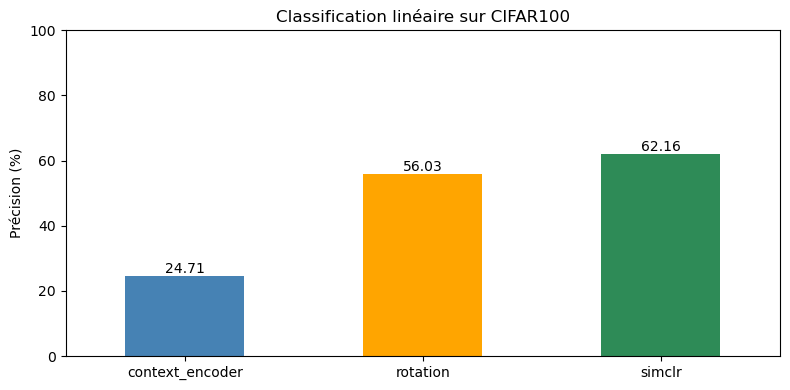

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

rows = []

for method in ["context_encoder", "rotation", "simclr"]:
    checkpoint = torch.load(
        Path("checkpoints") / f"{method}_cifar100_linear.pt",
        map_location="cpu",
        weights_only=True
    )

    rows.append({
        "Méthode": method,
        "Test Top-1 (%)": checkpoint["test_top1"],
        "Test Top-5 (%)": checkpoint.get("test_top5", float("nan"))
    })

cifar100_results = pd.DataFrame(rows)
display(cifar100_results)

ax = cifar100_results.plot.bar(
    x="Méthode",
    y="Test Top-1 (%)",
    legend=False,
    rot=0,
    figsize=(8, 4),
    color=["steelblue", "orange", "seagreen"]
)

ax.set_title("Classification linéaire sur CIFAR100")
ax.set_ylabel("Précision (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.2f")

plt.tight_layout()
plt.show()

#### Analyse des résultats

Sur CIFAR100, SimCLR obtient la meilleure précision Top-1
(62,16 %), devant Rotation Prediction (56,03 %) et
Context Encoder (24,71 %). Le classement est identique
à celui observé sur CIFAR10.

Ces résultats évaluent le transfert des encodeurs préentraînés :
seuls les nouveaux classifieurs sont entraînés sur CIFAR100.
Les différences d’architecture et de préentraînement limitent
l’attribution des écarts à la seule tâche auto-supervisée.

## 3. Prédiction de la position relative des patches
### Construction du dataset

In [67]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import CIFAR10
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt

class RelativePositionDataset(Dataset):
    def __init__(self, dataset, color_drop=True):
        self.dataset = dataset
        self.color_drop = color_drop

        self.positions = [
            (-1, -1), (-1, 0), (-1, 1),
            (0, -1),           (0, 1),
            (1, -1),  (1, 0),  (1, 1)
        ]

        self.patch_size = 8
        self.step = 12
        self.jitter = 1

    def __len__(self):
        return len(self.dataset)

    def transform_patch(self, patch):
        patch = TF.to_tensor(patch)

        if self.color_drop:
            # Conserver un canal, remplacer les deux autres par du bruit
            channel = torch.randint(0, 3, ()).item()
            kept = patch[channel].clone()
            noise_std = kept.std(unbiased=False) * 0.01

            noise = torch.randn_like(patch) * noise_std
            patch = noise + patch.mean(dim=(1, 2), keepdim=True)
            patch[channel] = kept
            patch = patch.clamp(0, 1)

        return (patch - 0.5) / 0.5

    def __getitem__(self, index):
        image, _ = self.dataset[index]
        width, height = image.size

        label = torch.randint(0, 8, ()).item()
        dy, dx = self.positions[label]

        p = self.patch_size
        s = self.step
        j = self.jitter

        # Choisir une origine permettant les deux patches et leur jitter
        row_min = j + max(0, -dy * s)
        row_max = height - p - j - max(0, dy * s)
        col_min = j + max(0, -dx * s)
        col_max = width - p - j - max(0, dx * s)

        row = torch.randint(row_min, row_max + 1, ()).item()
        col = torch.randint(col_min, col_max + 1, ()).item()

        offsets = torch.randint(-j, j + 1, (4,)).tolist()
        query_row, query_col = row + offsets[0], col + offsets[1]
        target_row = row + dy * s + offsets[2]
        target_col = col + dx * s + offsets[3]

        query = TF.crop(image, query_row, query_col, p, p)
        target = TF.crop(image, target_row, target_col, p, p)

        return (
            self.transform_patch(query),
            self.transform_patch(target),
            label
        )


patch_dataset = CIFAR10(
    root=r"G:\Vmi\M2\深度视觉\cs294-158-ssl\data\cifar10",
    train=True,
    download=False
)

relative_train_dataset = RelativePositionDataset(patch_dataset)

relative_train_loader = DataLoader(
    relative_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

query_batch, target_batch, position_labels = next(
    iter(relative_train_loader)
)

print("Requêtes :", query_batch.shape)
print("Voisins :", target_batch.shape)
print("Étiquettes :", position_labels.shape)

Requêtes : torch.Size([128, 3, 8, 8])
Voisins : torch.Size([128, 3, 8, 8])
Étiquettes : torch.Size([128])


In [68]:
import torch.nn as nn
from deepul_helper.tasks.rotation import RotationPrediction

# Réutiliser l'architecture de la librairie
NetworkInNetwork = RotationPrediction.__init__.__globals__["NetworkInNetwork"]

class RelativePositionModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = NetworkInNetwork()
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.position_head = nn.Sequential(
            nn.Linear(192 * 2, 256),
            nn.ReLU(),
            nn.Linear(256, 8)
        )

    def encode(self, images):
        features = self.encoder(
            images, out_feat_keys=("conv2",)
        )

        if isinstance(features, (list, tuple)):
            features = features[0]

        return self.pool(features).flatten(1)

    def forward(self, query, target):
        query_features = self.encode(query)
        target_features = self.encode(target)

        features = torch.cat(
            [query_features, target_features], dim=1
        )

        return self.position_head(features)


patch_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(42)
relative_model = RelativePositionModel().to(patch_device)

# Vérifier les dimensions sans modifier les statistiques BatchNorm
relative_model.eval()

with torch.no_grad():
    position_scores = relative_model(
        query_batch.to(patch_device),
        target_batch.to(patch_device)
    )

print("Scores de position :", position_scores.shape)

Scores de position : torch.Size([128, 8])


In [69]:
from tqdm.auto import tqdm
from pathlib import Path

patch_epochs = 10

patch_criterion = nn.CrossEntropyLoss()
patch_optimizer = torch.optim.Adam(
    relative_model.parameters(), lr=0.001
)

patch_history = []
patch_save_dir = Path("checkpoints")
patch_save_dir.mkdir(exist_ok=True)

for epoch in range(patch_epochs):
    relative_model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for query, target, labels in tqdm(
        relative_train_loader,
        desc=f"Epoch {epoch + 1}/{patch_epochs}"
    ):
        query = query.to(patch_device)
        target = target.to(patch_device)
        labels = labels.to(patch_device)

        patch_optimizer.zero_grad()

        logits = relative_model(query, target)
        loss = patch_criterion(logits, labels)

        loss.backward()
        patch_optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (
            logits.argmax(1) == labels
        ).sum().item()
        total_samples += batch_size

    epoch_loss = total_loss / total_samples
    epoch_acc = 100 * total_correct / total_samples

    patch_history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "position_accuracy": epoch_acc
    })

    print(
        f"Loss : {epoch_loss:.4f} | "
        f"Précision position : {epoch_acc:.2f} %",
        flush=True
    )

    # Sauvegarder après chaque époque
    torch.save({
        "model_state_dict": relative_model.state_dict(),
        "optimizer_state_dict": patch_optimizer.state_dict(),
        "epochs": epoch + 1,
        "history": patch_history,
        "pretrain_dataset": "cifar10",
        "patch_size": 8,
        "step": 12,
        "jitter": 1,
        "color_drop": True,
        "feature_dim": 192
    }, patch_save_dir / "relative_position_cifar10_v2.pt")

print("Entraînement terminé et modèle sauvegardé")

Epoch 1/10:   0%|          | 0/391 [00:00<?, ?it/s]

Loss : 2.0336 | Précision position : 16.35 %


Epoch 2/10:   0%|          | 0/391 [00:00<?, ?it/s]

Loss : 2.0092 | Précision position : 17.39 %


Epoch 3/10:   0%|          | 0/391 [00:00<?, ?it/s]

...

Loss : 1.9272 | Précision position : 21.42 %


Epoch 9/10:   0%|          | 0/391 [00:00<?, ?it/s]

Loss : 1.9176 | Précision position : 22.57 %


Epoch 10/10:   0%|          | 0/391 [00:00<?, ?it/s]

Loss : 1.9031 | Précision position : 23.84 %
Entraînement terminé et modèle sauvegardé


## 4. Évaluation des représentations
### Classification linéaire sur CIFAR10

In [70]:
from torchvision import transforms

# Images complètes, sans color dropping pour l'évaluation
relative_eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

relative_cifar10_root = (
    r"G:\Vmi\M2\深度视觉\cs294-158-ssl\data\cifar10"
)

relative_c10_train = CIFAR10(
    root=relative_cifar10_root,
    train=True,
    download=False,
    transform=relative_eval_transform
)

relative_c10_test = CIFAR10(
    root=relative_cifar10_root,
    train=False,
    download=False,
    transform=relative_eval_transform
)

relative_c10_train_loader = DataLoader(
    relative_c10_train,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

relative_c10_test_loader = DataLoader(
    relative_c10_test,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

relative_model.eval()
relative_model.requires_grad_(False)

images, labels = next(iter(relative_c10_train_loader))

with torch.no_grad():
    features = relative_model.encode(images.to(patch_device))

print("Images :", images.shape)
print("Caractéristiques :", features.shape)

Images : torch.Size([128, 3, 32, 32])
Caractéristiques : torch.Size([128, 192])


In [71]:
from tqdm.auto import tqdm

def extract_relative_features(loader):
    relative_model.eval()

    all_features = torch.empty(len(loader.dataset), 192)
    all_labels = torch.empty(len(loader.dataset), dtype=torch.long)
    offset = 0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Extraction"):
            features = relative_model.encode(
                images.to(patch_device)
            ).flatten(1)

            batch_size = labels.size(0)
            assert features.shape == (batch_size, 192)

            all_features[offset:offset + batch_size] = features.cpu()
            all_labels[offset:offset + batch_size] = labels.cpu()
            offset += batch_size

    return all_features, all_labels


relative_c10_X_train, relative_c10_y_train = (
    extract_relative_features(relative_c10_train_loader)
)

relative_c10_X_test, relative_c10_y_test = (
    extract_relative_features(relative_c10_test_loader)
)

print("Train :", relative_c10_X_train.shape)
print("Test :", relative_c10_X_test.shape)

Extraction:   0%|          | 0/391 [00:00<?, ?it/s]

Extraction:   0%|          | 0/79 [00:00<?, ?it/s]

Train : torch.Size([50000, 192])
Test : torch.Size([10000, 192])


### Entraînement du classifieur sur CIFAR10

In [73]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

relative_c10_feature_loader = DataLoader(
    TensorDataset(relative_c10_X_train, relative_c10_y_train),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

relative_c10_classifier = nn.Sequential(
    nn.BatchNorm1d(192, affine=False),
    nn.Linear(192, 10)
).to(patch_device)

relative_c10_optimizer = torch.optim.Adam(
    relative_c10_classifier.parameters(), lr=0.001
)

relative_c10_criterion = nn.CrossEntropyLoss()
relative_c10_epochs = 10

for epoch in range(relative_c10_epochs):
    relative_c10_classifier.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for features, labels in relative_c10_feature_loader:
        features = features.to(patch_device)
        labels = labels.to(patch_device)

        relative_c10_optimizer.zero_grad()

        logits = relative_c10_classifier(features)
        loss = relative_c10_criterion(logits, labels)

        loss.backward()
        relative_c10_optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_samples += batch_size

    print(
        f"Epoch {epoch + 1}/{relative_c10_epochs} | "
        f"Loss : {total_loss / total_samples:.4f} | "
        f"Précision train : {100 * total_correct / total_samples:.2f} %",
        flush=True
    )

Epoch 1/10 | Loss : 1.7969 | Précision train : 35.48 %
Epoch 2/10 | Loss : 1.6798 | Précision train : 40.14 %
Epoch 3/10 | Loss : 1.6412 | Précision train : 41.76 %
Epoch 4/10 | Loss : 1.6169 | Précision train : 42.36 %
Epoch 5/10 | Loss : 1.5988 | Précision train : 43.10 %
Epoch 6/10 | Loss : 1.5848 | Précision train : 43.65 %
Epoch 7/10 | Loss : 1.5758 | Précision train : 43.81 %
Epoch 8/10 | Loss : 1.5666 | Précision train : 43.95 %
Epoch 9/10 | Loss : 1.5591 | Précision train : 44.23 %
Epoch 10/10 | Loss : 1.5506 | Précision train : 44.69 %


In [74]:
from pathlib import Path

relative_c10_test_feature_loader = DataLoader(
    TensorDataset(relative_c10_X_test, relative_c10_y_test),
    batch_size=256,
    shuffle=False,
    num_workers=0
)

relative_c10_classifier.eval()
correct1 = 0
correct5 = 0
total = 0

with torch.no_grad():
    for features, labels in relative_c10_test_feature_loader:
        features = features.to(patch_device)
        labels = labels.to(patch_device)

        logits = relative_c10_classifier(features)
        top5 = logits.topk(5, dim=1).indices

        correct1 += (top5[:, 0] == labels).sum().item()
        correct5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()
        total += labels.size(0)

relative_c10_top1 = 100 * correct1 / total
relative_c10_top5 = 100 * correct5 / total

print(f"Position relative — CIFAR10 Top-1 : {relative_c10_top1:.2f} %")
print(f"Position relative — CIFAR10 Top-5 : {relative_c10_top5:.2f} %")

save_dir = Path("checkpoints")
save_dir.mkdir(exist_ok=True)

torch.save({
    "method": "relative_position",
    "dataset": "cifar10",
    "classifier_state_dict": relative_c10_classifier.state_dict(),
    "input_dim": 192,
    "n_classes": 10,
    "epochs": relative_c10_epochs,
    "test_top1": relative_c10_top1,
    "test_top5": relative_c10_top5
}, save_dir / "relative_position_cifar10_linear.pt")

print("Classifieur et résultats sauvegardés")

Position relative — CIFAR10 Top-1 : 44.78 %
Position relative — CIFAR10 Top-5 : 90.74 %
Classifieur et résultats sauvegardés


### Classification linéaire sur CIFAR100

In [75]:
from torchvision.datasets import CIFAR100

relative_c100_train = CIFAR100(
    root="data",
    train=True,
    download=False,
    transform=relative_eval_transform
)

relative_c100_test = CIFAR100(
    root="data",
    train=False,
    download=False,
    transform=relative_eval_transform
)

relative_c100_train_loader = DataLoader(
    relative_c100_train,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

relative_c100_test_loader = DataLoader(
    relative_c100_test,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

relative_c100_X_train, relative_c100_y_train = (
    extract_relative_features(relative_c100_train_loader)
)

relative_c100_X_test, relative_c100_y_test = (
    extract_relative_features(relative_c100_test_loader)
)

print("Train :", relative_c100_X_train.shape)
print("Test :", relative_c100_X_test.shape)

Extraction:   0%|          | 0/391 [00:00<?, ?it/s]

Extraction:   0%|          | 0/79 [00:00<?, ?it/s]

Train : torch.Size([50000, 192])
Test : torch.Size([10000, 192])


In [76]:
torch.manual_seed(42)

relative_c100_feature_loader = DataLoader(
    TensorDataset(relative_c100_X_train, relative_c100_y_train),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

relative_c100_classifier = nn.Sequential(
    nn.BatchNorm1d(192, affine=False),
    nn.Linear(192, 100)
).to(patch_device)

relative_c100_optimizer = torch.optim.Adam(
    relative_c100_classifier.parameters(), lr=0.001
)

relative_c100_criterion = nn.CrossEntropyLoss()
relative_c100_epochs = 10

for epoch in range(relative_c100_epochs):
    relative_c100_classifier.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for features, labels in relative_c100_feature_loader:
        features = features.to(patch_device)
        labels = labels.to(patch_device)

        relative_c100_optimizer.zero_grad()
        logits = relative_c100_classifier(features)
        loss = relative_c100_criterion(logits, labels)

        loss.backward()
        relative_c100_optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(1) == labels).sum().item()
        total_samples += batch_size

    print(
        f"Epoch {epoch + 1}/{relative_c100_epochs} | "
        f"Loss : {total_loss / total_samples:.4f} | "
        f"Précision train : {100 * total_correct / total_samples:.2f} %",
        flush=True
    )

Epoch 1/10 | Loss : 4.0559 | Précision train : 8.98 %
Epoch 2/10 | Loss : 3.8616 | Précision train : 12.37 %
Epoch 3/10 | Loss : 3.7948 | Précision train : 13.65 %
Epoch 4/10 | Loss : 3.7536 | Précision train : 14.37 %
Epoch 5/10 | Loss : 3.7212 | Précision train : 15.22 %
Epoch 6/10 | Loss : 3.6917 | Précision train : 15.79 %
Epoch 7/10 | Loss : 3.6689 | Précision train : 15.88 %
Epoch 8/10 | Loss : 3.6491 | Précision train : 16.34 %
Epoch 9/10 | Loss : 3.6331 | Précision train : 16.57 %
Epoch 10/10 | Loss : 3.6163 | Précision train : 16.89 %


In [77]:
relative_c100_test_feature_loader = DataLoader(
    TensorDataset(relative_c100_X_test, relative_c100_y_test),
    batch_size=256,
    shuffle=False,
    num_workers=0
)

relative_c100_classifier.eval()
correct1 = 0
correct5 = 0
total = 0

with torch.no_grad():
    for features, labels in relative_c100_test_feature_loader:
        features = features.to(patch_device)
        labels = labels.to(patch_device)

        logits = relative_c100_classifier(features)
        top5 = logits.topk(5, dim=1).indices

        correct1 += (top5[:, 0] == labels).sum().item()
        correct5 += (
            top5 == labels.unsqueeze(1)
        ).any(dim=1).sum().item()
        total += labels.size(0)

relative_c100_top1 = 100 * correct1 / total
relative_c100_top5 = 100 * correct5 / total

print(f"Position relative — CIFAR100 Top-1 : {relative_c100_top1:.2f} %")
print(f"Position relative — CIFAR100 Top-5 : {relative_c100_top5:.2f} %")

from pathlib import Path

save_dir = Path("checkpoints")
save_dir.mkdir(exist_ok=True)

torch.save({
    "method": "relative_position",
    "dataset": "cifar100",
    "classifier_state_dict": relative_c100_classifier.state_dict(),
    "input_dim": 192,
    "n_classes": 100,
    "epochs": relative_c100_epochs,
    "test_top1": relative_c100_top1,
    "test_top5": relative_c100_top5
}, save_dir / "relative_position_cifar100_linear.pt")

print("Classifieur et résultats sauvegardés")

Position relative — CIFAR100 Top-1 : 16.84 %
Position relative — CIFAR100 Top-5 : 40.68 %
Classifieur et résultats sauvegardés


,Méthode,CIFAR10,CIFAR100
0,Context Encoder,45.77,24.71
1,Rotation,79.91,56.03
2,SimCLR,92.84,62.16
3,Position relative,44.78,16.84


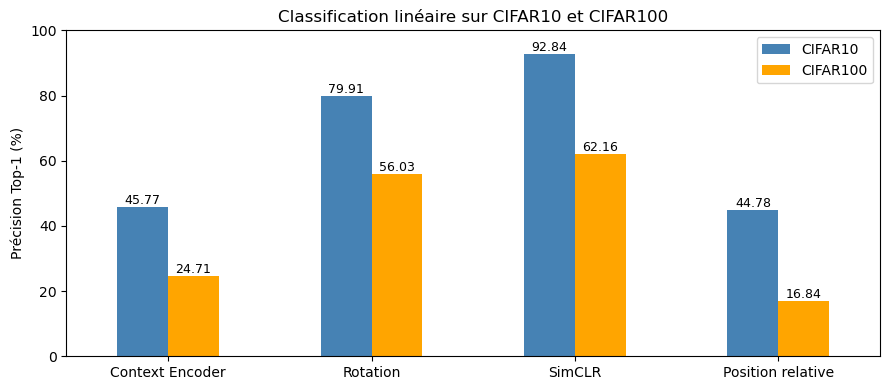

Figure enregistrée : G:\Vmi\M2\深度视觉\comparaison_finale.png


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Résultats obtenus lors des expériences
comparison = pd.DataFrame({
    "Méthode": [
        "Context Encoder",
        "Rotation",
        "SimCLR",
        "Position relative"
    ],
    "CIFAR10": [45.77, 79.91, 92.84, 44.78],
    "CIFAR100": [24.71, 56.03, 62.16, 16.84]
})

display(comparison)

ax = comparison.set_index("Méthode").plot.bar(
    figsize=(9, 4),
    rot=0,
    color=["steelblue", "orange"]
)

ax.set_title("Classification linéaire sur CIFAR10 et CIFAR100")
ax.set_ylabel("Précision Top-1 (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9)

plt.tight_layout()

output_path = Path.cwd() / "comparaison_finale.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure enregistrée :", output_path)

### Conclusion

SimCLR obtient la meilleure précision sur les deux jeux de données,
suivi de Rotation et du Context Encoder. Notre méthode de position
relative atteint 44,78 % sur CIFAR10 et 16,84 % sur CIFAR100.

La tâche de position relative permet donc d’apprendre des caractéristiques
utiles à la classification, mais leur efficacité reste limitée dans
notre configuration.

Cette comparaison n’isole pas l’effet de la tâche prétexte :
les architectures, les dimensions des caractéristiques et les conditions
de préentraînement diffèrent. Notre modèle utilise notamment des patches
de 8 × 8 et seulement dix époques de préentraînement sur CIFAR10.
L’évaluation sur CIFAR100 mesure le transfert de ces représentations,
sans nouveau préentraînement auto-supervisé.